# Engagement 2: Mobile Money Agent Network

## Data Cleaning, Validation and Analysis

**PLP Data Analysis, Week 3 Assignment** | Student: Nelly Mwangi

A regional manager wants to know which agents and counties handle the most deposits and withdrawals, but the legacy transaction extract is unreliable. This notebook audits the extract, cleans it with the reusable function `clean_agent_data()` in `cleaning_pipeline.py`, merges it with the agent register, and produces county and weekly summaries. A Data Quality Report organised by the six dimensions is at the end.

**Regenerate the data first:** `python generate_data.py` (seed 44 for this engagement).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## Task 1: Load and Inspect the Raw Data

First look at both files: shape, types, missing values, label variants and date formats.

In [2]:
txns = pd.read_csv("agent_transactions.csv")
agents = pd.read_csv("agents.csv")

print("Transaction data shape:", txns.shape)
print("Agent register shape:", agents.shape)

display(txns.head())
display(agents.head())

Transaction data shape: (612, 5)
Agent register shape: (20, 3)


,txn_id,agent_id,txn_type,amount,txn_date
0,TX00001,AG009,deposit,353.00,2026-03-03
1,TX00002,AG020,deposit,"1,238.00",2026-04-27
2,TX00003,AG008,DEPOSIT,"9,129.00",2026-04-29
3,TX00004,AG009,deposit,652.00,2026-04-24
4,TX00005,AG009,withdrawal,478.00,2026-04-17


,agent_id,county,onboarded
0,AG001,Mombasa,2024-01-01
1,AG002,Nairobi,2024-02-01
2,AG003,Kisumu,2024-03-01
3,AG004,Kiambu,2024-04-01
4,AG005,Mombasa,2024-05-01


In [3]:
print("TRANSACTION DATA INFORMATION")
txns.info()

print("\nAGENT REGISTER INFORMATION")
agents.info()

print("\nMissing values in transactions:")
display(txns.isnull().sum())

print("\nTransaction type counts:")
display(txns["txn_type"].value_counts(dropna=False))

print("\nTransaction date examples:")
display(txns["txn_date"].head(10))

TRANSACTION DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   txn_id    612 non-null    str    
 1   agent_id  612 non-null    str    
 2   txn_type  612 non-null    str    
 3   amount    590 non-null    float64
 4   txn_date  612 non-null    str    
dtypes: float64(1), str(4)
memory usage: 24.0 KB

AGENT REGISTER INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   agent_id   20 non-null     str  
 1   county     20 non-null     str  
 2   onboarded  20 non-null     str  
dtypes: str(3)
memory usage: 612.0 bytes

Missing values in transactions:


txn_id       0
agent_id     0
txn_type     0
amount      22
txn_date     0
dtype: int64


Transaction type counts:


txn_type
deposit       142
withdrawal    131
Deposit       128
DEPOSIT       111
Withdrawal    100
Name: count, dtype: int64


Transaction date examples:


0    2026-03-03
1    2026-04-27
2    2026-04-29
3    2026-04-24
4    2026-04-17
5    2026-04-23
6    2026-04-02
7    2026-04-12
8    2026-04-04
9    2026-04-17
Name: txn_date, dtype: str

## Task 2: Data-Quality Audit Table

The audit counts each problem on the **raw** extract (612 rows). Note that pandas reads the text `N/A` as missing by default, so I re-read `amount` as plain text (`keep_default_na=False`) to separate genuinely blank cells from the text `N/A`, then check `isna()` as well. The 12 duplicate rows also repeat any problem they carry (for example two of the duplicated rows hold `N/A`), so the counts below are on raw rows; the counts after cleaning are in the pipeline log.

In [4]:
raw_text = pd.read_csv("agent_transactions.csv", dtype=str, keep_default_na=False)

amount_num = pd.to_numeric(txns["amount"], errors="coerce")

blank_amounts  = (raw_text["amount"].str.strip() == "").sum()          # truly empty cells
na_text        = (raw_text["amount"].str.strip().str.upper() == "N/A").sum()  # text "N/A"
missing_after_read = txns["amount"].isna().sum()                       # what isna() sees

dup_rows       = txns.duplicated(subset="txn_id", keep="first").sum()
type_clean     = txns["txn_type"].astype("string").str.strip().str.lower()
type_variants  = (txns["txn_type"].astype("string") != type_clean.map({"deposit": "Deposit", "withdrawal": "Withdrawal"})).sum()
slash_dates    = txns["txn_date"].astype("string").str.contains("/", na=False).sum()
amt_250k       = (amount_num == 250000).sum()
unknown_raw    = (~txns["agent_id"].isin(agents["agent_id"])).sum()

audit_table = pd.DataFrame([
    {"issue": "Blank (missing) transaction amounts",               "dimension": "Completeness", "column": "amount",   "rows affected": int(blank_amounts)},
    {"issue": 'Text "N/A" in amount (pandas reads it as NaN)',     "dimension": "Completeness", "column": "amount",   "rows affected": int(na_text)},
    {"issue": "Duplicate transaction rows (same txn_id)",          "dimension": "Uniqueness",   "column": "txn_id",   "rows affected": int(dup_rows)},
    {"issue": "Mixed case / trailing spaces in transaction type",  "dimension": "Consistency",  "column": "txn_type", "rows affected": int(type_variants)},
    {"issue": "Dates written with / instead of -",                 "dimension": "Validity",     "column": "txn_date", "rows affected": int(slash_dates)},
    {"issue": "Amount stored as text, not numeric",                "dimension": "Validity",     "column": "amount",   "rows affected": int(len(raw_text))},
    {"issue": "Agent ID not in the agent register (AG099)",        "dimension": "Validity",     "column": "agent_id", "rows affected": int(unknown_raw)},
    {"issue": "Suspicious amounts of exactly KES 250,000",         "dimension": "Accuracy",     "column": "amount",   "rows affected": int(amt_250k)},
])
print("isna() on amount after read_csv:", missing_after_read, "= blanks + N/A text:", blank_amounts + na_text)
display(audit_table)

isna() on amount after read_csv: 22 = blanks + N/A text: 22


,issue,dimension,column,rows affected
0,Blank (missing) transaction amounts,Completeness,amount,15
1,"Text ""N/A"" in amount (pandas reads it as NaN)",Completeness,amount,7
2,Duplicate transaction rows (same txn_id),Uniqueness,txn_id,12
3,Mixed case / trailing spaces in transaction type,Consistency,txn_type,384
4,Dates written with / instead of -,Validity,txn_date,5
5,"Amount stored as text, not numeric",Validity,amount,612
6,Agent ID not in the agent register (AG099),Validity,agent_id,8
7,"Suspicious amounts of exactly KES 250,000",Accuracy,amount,5


**Timeliness:** all dates fall in a single 60-day window (checked after cleaning, see the report). No rows fall outside the expected period, so no timeliness issue was injected.

## Task 3 to 8: Run the Cleaning Pipeline

All rules live in `clean_agent_data(txns, agents)` and return `(clean_df, log)`: de-duplication on `txn_id`, `txn_type` standardisation, numeric conversion, median imputation with an `amount_imputed` flag, IQR outlier flagging (`is_outlier`), date standardisation, and a left join to the agent register. No row numbers are hard-coded.

In [5]:
from cleaning_pipeline import clean_agent_data

clean_df, cleaning_log = clean_agent_data(txns, agents)

print("CLEANING PIPELINE LOG")
for item in cleaning_log:
    print("-", item)

print("\nCleaned dataset shape:", clean_df.shape)

display(clean_df.head())

CLEANING PIPELINE LOG
- Original transaction rows: 612
- Duplicate transactions removed: 12
- Transaction types standardised to Deposit and Withdrawal.
- Missing or invalid amounts (NaN or text such as N/A) imputed with the median of observed amounts, KES 1,776 (20 rows, flagged in amount_imputed).
- IQR limits on observed amounts: -1,928 to 6,084. Outliers flagged: 40, of which 5 are exactly KES 250,000. Outliers retained for review.
- Transaction dates standardised to YYYY-MM-DD (5 rows used slash separators).
- Transactions with unknown agent IDs: 7. Kept (left join) and labelled county = Unknown.
- Final cleaned transaction rows: 600

Cleaned dataset shape: (600, 8)


,txn_id,agent_id,txn_type,amount,txn_date,amount_imputed,is_outlier,county
0,TX00001,AG009,Deposit,353.00,2026-03-03,False,False,Nakuru
1,TX00002,AG020,Deposit,"1,238.00",2026-04-27,False,False,Mombasa
2,TX00003,AG008,Deposit,"9,129.00",2026-04-29,False,True,Kisumu
3,TX00004,AG009,Deposit,652.00,2026-04-24,False,False,Nakuru
4,TX00005,AG009,Withdrawal,478.00,2026-04-17,False,False,Nakuru


### Uniqueness
12 rows repeated an existing `txn_id`. Eleven are exact copies of the original row; one copy differs only in `agent_id` (the unknown agent `AG099` was written into the copy), so it is the same transaction and keeping the first occurrence loses nothing. **12 removed**, leaving 600 unique transactions (612 to 600).

In [6]:
dups = txns[txns.duplicated(subset="txn_id", keep=False)]
exact_copies = txns.duplicated(keep="first").sum()
print("Rows sharing a txn_id:", len(dups), "| exact full-row duplicates:", exact_copies)
print("Rows before:", len(txns), "| after:", len(clean_df), "| removed:", len(txns) - len(clean_df))

Rows sharing a txn_id: 24 | exact full-row duplicates: 11
Rows before: 612 | after: 600 | removed: 12


### Consistency
`txn_type` had five spellings (`Deposit`, `DEPOSIT `, `deposit`, `withdrawal`, `Withdrawal`). After `strip()` and `lower()` they map to exactly two values, **Deposit** and **Withdrawal**.

In [7]:
print("Before:", sorted(txns["txn_type"].unique().tolist()))
print("After :", sorted(clean_df["txn_type"].unique().tolist()))

Before: ['DEPOSIT ', 'Deposit', 'Withdrawal', 'deposit', 'withdrawal']
After : ['Deposit', 'Withdrawal']


### Validity and types
`amount` arrived as text and was converted with `pd.to_numeric(errors="coerce")`, which turns `N/A` and blanks into missing values rather than crashing. `txn_date` used two formats (`2026-03-01` and `2026/03/01`); the separator was normalised and parsed with an explicit `format="%Y-%m-%d"`, and the pipeline raises an error if any date still fails to parse, so nothing is silently lost.

In [8]:
print(clean_df.dtypes[["amount", "txn_date"]])
print("Unparsed dates:", clean_df["txn_date"].isna().sum())

amount             float64
txn_date    datetime64[us]
dtype: object
Unparsed dates: 0


### Completeness: missing and invalid amounts
**Decision: impute with the median of the observed amounts and flag every imputed row** (`amount_imputed = True`).

*Why the median:* amounts are right-skewed (a few very large values), so the mean would be pulled up by the KES 250,000 entries; the median (about KES 1,776) is a more typical value. *Why not drop the rows:* the transaction still happened and its type, date and agent are valid, so dropping would understate transaction counts and distort the county and weekly counts. *Why not keep as NaN:* sums would silently ignore them.

*Trade-off:* imputed values add about KES 35,500 of invented value (20 x 1,776), which is only 1.3% of total value, and it is clearly marked so analysts can exclude those rows with `amount_imputed == False`.

In [9]:
print("Imputed rows:", int(clean_df["amount_imputed"].sum()), "of", len(clean_df))
imp_val = clean_df.loc[clean_df["amount_imputed"], "amount"].sum()
print(f"Imputed value: KES {imp_val:,.0f} = {imp_val / clean_df['amount'].sum():.1%} of total value")
display(clean_df[clean_df["amount_imputed"]].head())

Imputed rows: 20 of 600
Imputed value: KES 35,530 = 1.3% of total value


,txn_id,agent_id,txn_type,amount,txn_date,amount_imputed,is_outlier,county
10,TX00011,AG009,Withdrawal,"1,776.50",2026-03-27,True,False,Nakuru
14,TX00015,AG003,Deposit,"1,776.50",2026-03-18,True,False,Kisumu
54,TX00055,AG012,Withdrawal,"1,776.50",2026-03-19,True,False,Kisumu
66,TX00067,AG002,Deposit,"1,776.50",2026-04-07,True,False,Nairobi
122,TX00123,AG008,Deposit,"1,776.50",2026-04-15,True,False,Kisumu


### Outliers (IQR method) and the KES 250,000 values
IQR limits are calculated on the **observed** amounts *before* imputation. (Computing them after filling 20 gaps with the median narrows the IQR and wrongly raises the outlier count from 40 to 53.) Imputed rows are never flagged.

In [10]:
obs = pd.to_numeric(txns.drop_duplicates("txn_id")["amount"], errors="coerce").dropna()
q1, q3 = obs.quantile([0.25, 0.75]); iqr = q3 - q1
print(f"Q1={q1:,.0f}  Q3={q3:,.0f}  IQR={iqr:,.0f}  upper limit={q3 + 1.5*iqr:,.0f}")
print("Outliers flagged:", int(clean_df["is_outlier"].sum()))

big = clean_df[clean_df["amount"] == 250000]
print("\nKES 250,000 rows:", len(big), "| distinct agents:", big["agent_id"].nunique(), "| types:", big["txn_type"].value_counts().to_dict())
print(f"Share of total value: {big['amount'].sum() / clean_df['amount'].sum():.1%}")
print(f"Largest other amount: KES {clean_df.loc[clean_df['amount'] != 250000, 'amount'].max():,.0f}")
print(f"Multiple of the median: {250000 / clean_df['amount'].median():,.0f}x")
display(big)

Q1=1,077  Q3=3,080  IQR=2,003  upper limit=6,084
Outliers flagged: 40

KES 250,000 rows: 5 | distinct agents: 5 | types: {'Deposit': 3, 'Withdrawal': 2}
Share of total value: 46.5%
Largest other amount: KES 28,847
Multiple of the median: 141x


,txn_id,agent_id,txn_type,amount,txn_date,amount_imputed,is_outlier,county
306,TX00307,AG012,Deposit,"250,000.00",2026-03-02,False,True,Kisumu
315,TX00316,AG014,Deposit,"250,000.00",2026-04-01,False,True,Nairobi
424,TX00425,AG005,Withdrawal,"250,000.00",2026-03-02,False,True,Mombasa
463,TX00464,AG009,Withdrawal,"250,000.00",2026-04-11,False,True,Nakuru
594,TX00595,AG016,Deposit,"250,000.00",2026-03-11,False,True,Kiambu


**Investigation and recommendation.** Five transactions are exactly KES 250,000. The next-largest legitimate amount is only about KES 28,800 and the median is about KES 1,800, so each is roughly 140 times the median, and together they make up about 46% of all transaction value. The identical round figure, appearing on different agents and dates, looks like a system default or a manual keying error, not natural variation. A single value of 250,000 is also the figure often used as a daily or per-transaction mobile-money limit, so it could be a capped or placeholder entry.

**Recommendation:** do not delete them and do not silently trust them. They are kept in the cleaned file with `is_outlier = True`. The business should (1) trace the five `txn_id`s back to the source system or agent receipts, (2) correct or remove them once verified, and (3) until then report totals both with and without outliers. County rankings are sensitive to these five rows, so conclusions below should be read with that caveat. The other 35 flagged values are high but plausible for a right-skewed distribution and are retained.

## Task 7: Merge with the Agent Register and Validate

A **left join** from transactions to the register is used so every transaction is kept even if its agent is unknown (an inner join would silently drop transactions and understate totals). The register has unique `agent_id`s, so the join is validated as many-to-one and cannot multiply rows. Eight raw rows reference `AG099`, which is not in the register; one of them was a duplicate, so seven remain after de-duplication. They are kept and labelled `county = "Unknown"` rather than guessed.

In [11]:
dedup = txns.drop_duplicates(subset="txn_id")
merged_check = dedup.merge(agents[["agent_id", "county"]], on="agent_id", how="left", validate="many_to_one", indicator=True)

print("Rows before merge (after de-dup):", len(dedup))
print("Rows after merge                :", len(merged_check))
print("Rows in clean_df                :", len(clean_df))
print("Agent register rows / unique IDs:", len(agents), "/", agents["agent_id"].nunique())
print("Transactions with unknown agent :", int((clean_df["county"] == "Unknown").sum()))
print("Unknown agent IDs               :", sorted(merged_check.loc[merged_check["_merge"] == "left_only", "agent_id"].unique()))
assert len(dedup) == len(merged_check) == len(clean_df)
display(merged_check["_merge"].value_counts())

Rows before merge (after de-dup): 600
Rows after merge                : 600
Rows in clean_df                : 600
Agent register rows / unique IDs: 20 / 20
Transactions with unknown agent : 7
Unknown agent IDs               : ['AG099']


_merge
both          593
left_only       7
right_only      0
Name: count, dtype: int64

In [12]:
print("POST-CLEANING VALIDATION")

print(
    "Number of rows:",
    len(clean_df)
)

print(
    "Duplicate transaction IDs:",
    clean_df["txn_id"].duplicated().sum()
)

print(
    "Transaction types:",
    clean_df["txn_type"].unique()
)

print(
    "Amount data type:",
    clean_df["amount"].dtype
)

print(
    "Missing amounts:",
    clean_df["amount"].isna().sum()
)

print(
    "Missing transaction dates:",
    clean_df["txn_date"].isna().sum()
)

print(
    "Unknown agent transactions:",
    (clean_df["county"] == "Unknown").sum()
)

print(
    "Imputed amounts:",
    clean_df["amount_imputed"].sum()
)

print(
    "Flagged outliers:",
    clean_df["is_outlier"].sum()
)

POST-CLEANING VALIDATION
Number of rows: 600
Duplicate transaction IDs: 0
Transaction types: <StringArray>
['Deposit', 'Withdrawal']
Length: 2, dtype: str
Amount data type: float64
Missing amounts: 0
Missing transaction dates: 0
Unknown agent transactions: 7
Imputed amounts: 20
Flagged outliers: 40


In [13]:
Path("outputs").mkdir(exist_ok=True)

export_df = clean_df.copy()

export_df["txn_date"] = (
    export_df["txn_date"].dt.strftime("%Y-%m-%d")
)

export_df.to_csv(
    "outputs/agent_transactions_clean.csv",
    index=False
)

print("Cleaned agent transactions exported successfully.")

Cleaned agent transactions exported successfully.


## Task 8: Summaries

### (a) County summary by transaction type
Total value, number of transactions and average value for each county, split by Deposit and Withdrawal. `Unknown` holds the transactions from agents missing in the register.

In [14]:

county_summary = (
    clean_df.groupby(["county", "txn_type"])
    .agg(
        total_value=("amount", "sum"),
        number_of_transactions=("txn_id", "count"),
        average_value=("amount", "mean")
    )
    .reset_index()
)

county_summary["total_value"] = county_summary["total_value"].round(2)
county_summary["average_value"] = county_summary["average_value"].round(2)

display(county_summary)


,county,txn_type,total_value,number_of_transactions,average_value
0,Kiambu,Deposit,"334,737.00",43,"7,784.58"
1,Kiambu,Withdrawal,"77,050.50",27,"2,853.72"
2,Kisumu,Deposit,"436,420.50",74,"5,897.57"
3,Kisumu,Withdrawal,"76,374.50",37,"2,064.18"
4,Mombasa,Deposit,"148,986.00",72,"2,069.25"
5,Mombasa,Withdrawal,"368,592.00",61,"6,042.49"
6,Nairobi,Deposit,"543,590.00",118,"4,606.69"
7,Nairobi,Withdrawal,"162,036.00",62,"2,613.48"
8,Nakuru,Deposit,"184,890.00",60,"3,081.50"
9,Nakuru,Withdrawal,"328,594.50",39,"8,425.50"


In [15]:

county_totals = (
    clean_df.groupby("county")
    .agg(
        total_value=("amount", "sum"),
        number_of_transactions=("txn_id", "count"),
        average_value=("amount", "mean")
    )
    .sort_values("total_value", ascending=False)
)

display(county_totals.round(2))


,total_value,number_of_transactions,average_value
county,,,
Nairobi,"705,626.00",180,"3,920.14"
Mombasa,"517,578.00",133,"3,891.56"
Nakuru,"513,484.50",99,"5,186.71"
Kisumu,"512,795.00",111,"4,619.77"
Kiambu,"411,787.50",70,"5,882.68"
Unknown,"27,156.00",7,"3,879.43"


In [16]:

top_county = county_totals["total_value"].idxmax()
top_county_value = county_totals.loc[top_county, "total_value"]

print("County with the highest transaction value:", top_county)
print(f"Total transaction value: KES {top_county_value:,.2f}")


County with the highest transaction value: Nairobi
Total transaction value: KES 705,626.00


### (b) Weekly transaction value by county (pivot table)

In [17]:

clean_df["week"] = (
    clean_df["txn_date"]
    .dt.to_period("W")
    .astype(str)
)

display(clean_df[["txn_date", "week", "county", "amount"]].head())


,txn_date,week,county,amount
0,2026-03-03,2026-03-02/2026-03-08,Nakuru,353.00
1,2026-04-27,2026-04-27/2026-05-03,Mombasa,"1,238.00"
2,2026-04-29,2026-04-27/2026-05-03,Kisumu,"9,129.00"
3,2026-04-24,2026-04-20/2026-04-26,Nakuru,652.00
4,2026-04-17,2026-04-13/2026-04-19,Nakuru,478.00


In [18]:

weekly_pivot = clean_df.pivot_table(
    index="week",
    columns="county",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

display(weekly_pivot.round(2))


county,Kiambu,Kisumu,Mombasa,Nairobi,Nakuru,Unknown
week,,,,,,
2026-02-23/2026-03-01,0.00,"1,893.00","6,759.00","7,046.00","2,743.50",0.00
2026-03-02/2026-03-08,"18,317.00","287,933.00","285,669.50","68,967.00","56,574.00",0.00
2026-03-09/2026-03-15,"267,771.50","23,186.00","30,477.50","52,860.50","28,730.00",0.00
2026-03-16/2026-03-22,"22,054.00","28,125.00","25,144.50","43,107.50","39,795.00","1,639.00"
2026-03-23/2026-03-29,"11,504.00","27,077.00","17,050.00","41,373.50","18,998.50",0.00
2026-03-30/2026-04-05,"22,609.00","41,077.00","38,344.00","282,931.00","18,145.00","8,507.00"
2026-04-06/2026-04-12,"15,030.00","15,341.00","47,092.50","56,786.50","276,609.00","9,824.00"
2026-04-13/2026-04-19,"12,265.00","29,416.00","26,730.00","56,432.50","26,152.50",0.00
2026-04-20/2026-04-26,"24,507.00","37,439.00","16,687.00","65,187.00","30,862.00","1,877.00"


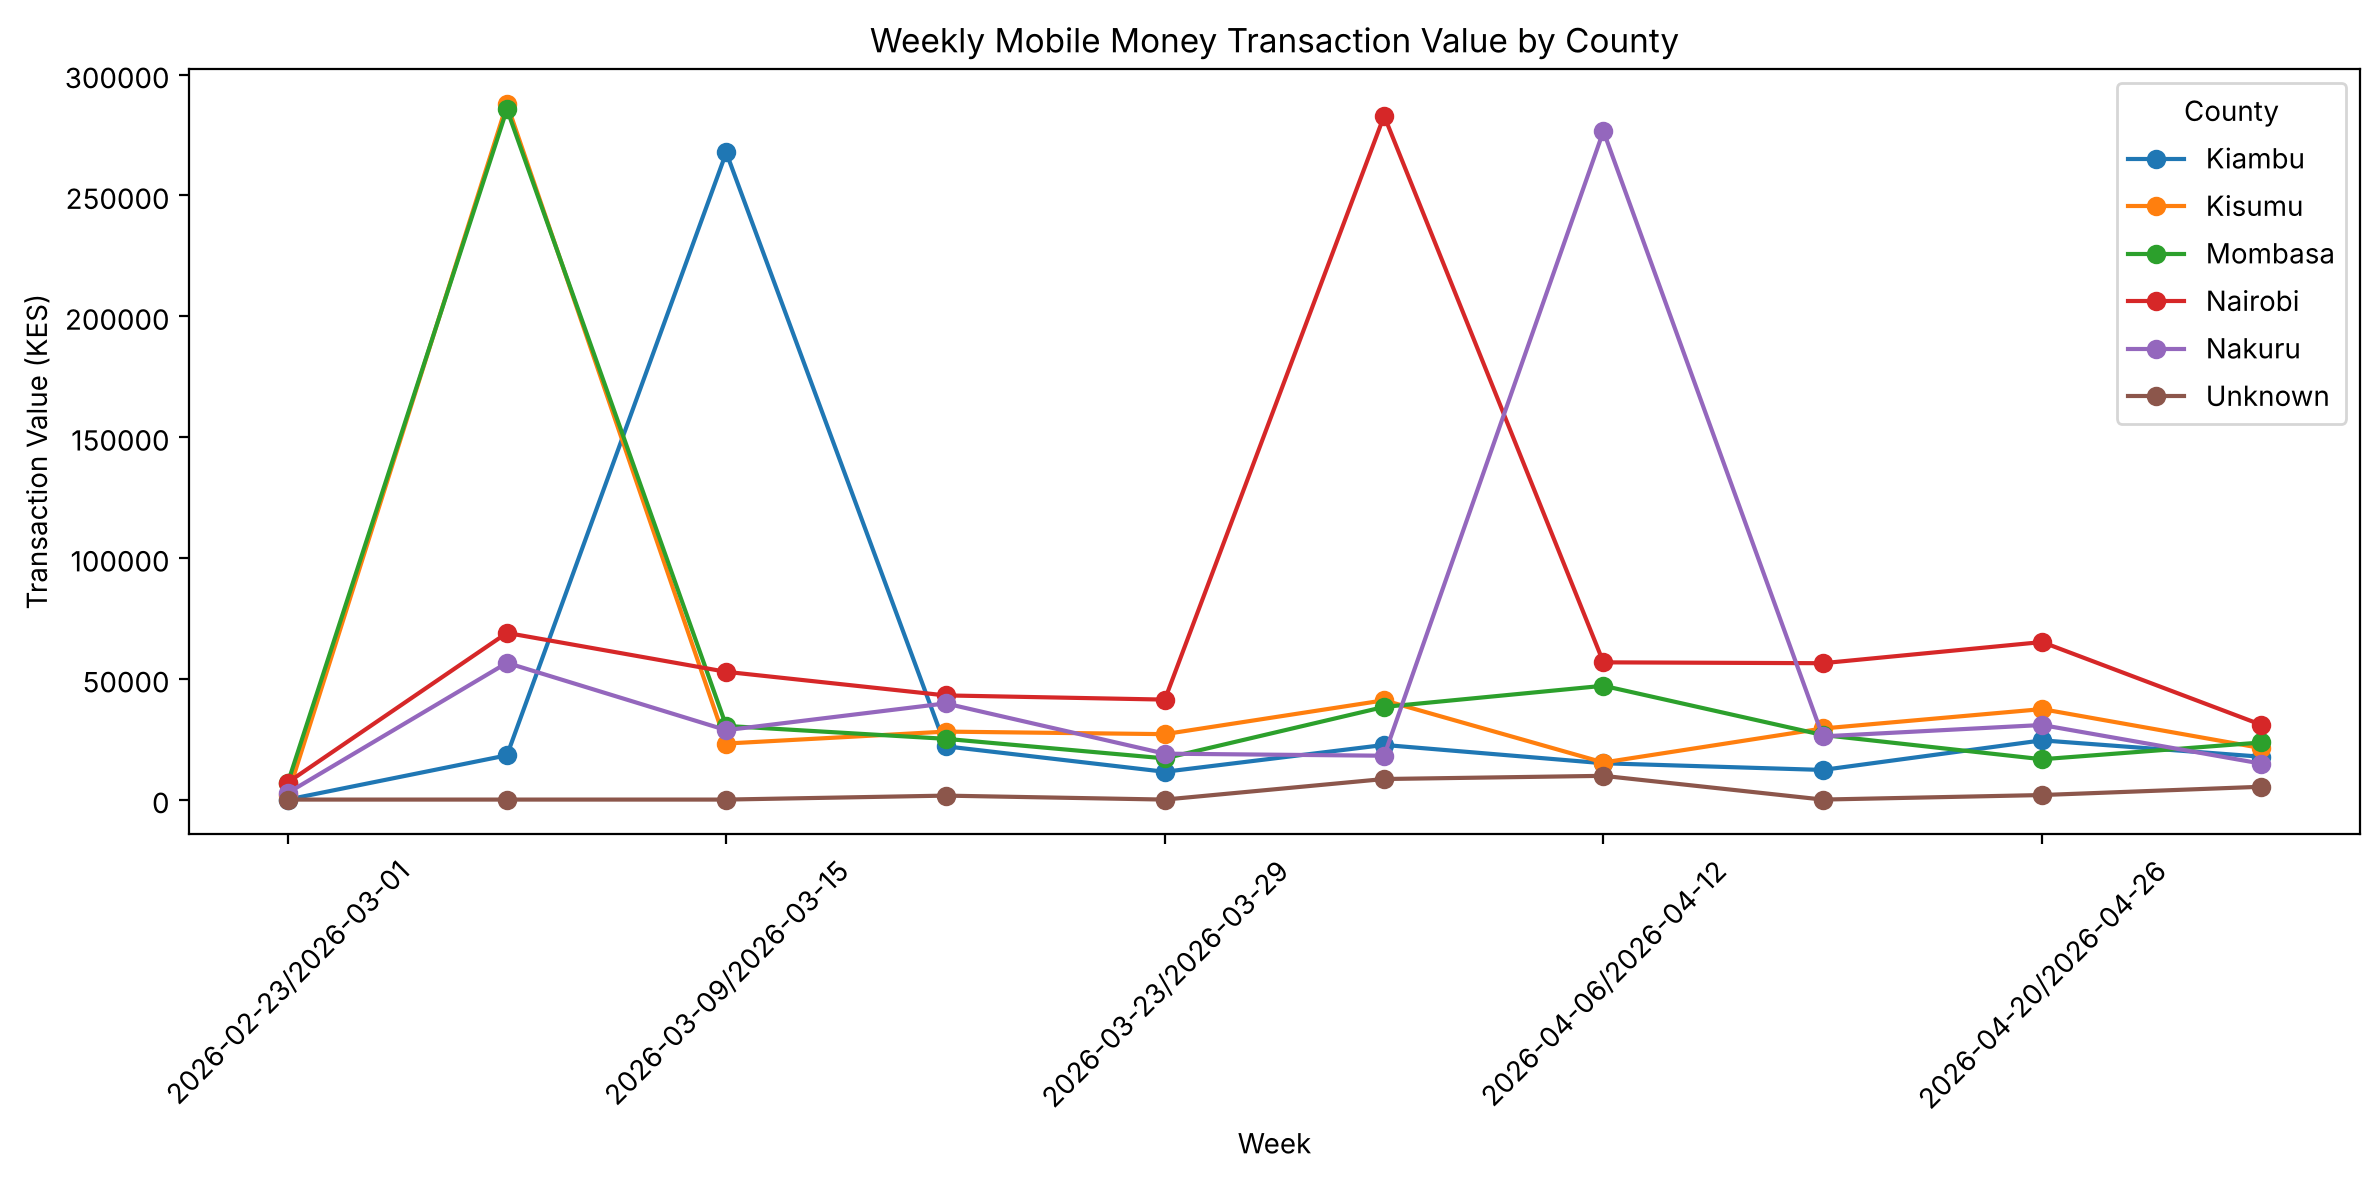

In [19]:

import matplotlib.pyplot as plt

weekly_pivot.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Weekly Mobile Money Transaction Value by County")
plt.xlabel("Week")
plt.ylabel("Transaction Value (KES)")
plt.xticks(rotation=45)
plt.legend(title="County")
plt.tight_layout()
plt.show()


## Business Insights

In [20]:

total_transactions = len(clean_df)
total_transaction_value = clean_df["amount"].sum()
average_transaction_value = clean_df["amount"].mean()

deposit_data = clean_df[clean_df["txn_type"] == "Deposit"]
withdrawal_data = clean_df[clean_df["txn_type"] == "Withdrawal"]

print("MOBILE MONEY AGENT NETWORK SUMMARY")
print("-----------------------------------")
print(f"Total transactions: {total_transactions:,}")
print(f"Total transaction value: KES {total_transaction_value:,.2f}")
print(f"Average transaction value: KES {average_transaction_value:,.2f}")

print("\nDEPOSITS")
print(f"Number of deposits: {len(deposit_data):,}")
print(f"Deposit value: KES {deposit_data['amount'].sum():,.2f}")

print("\nWITHDRAWALS")
print(f"Number of withdrawals: {len(withdrawal_data):,}")
print(f"Withdrawal value: KES {withdrawal_data['amount'].sum():,.2f}")

print("\nTOP COUNTY")
print(f"{top_county}: KES {top_county_value:,.2f}")


MOBILE MONEY AGENT NETWORK SUMMARY
-----------------------------------
Total transactions: 600
Total transaction value: KES 2,688,427.00
Average transaction value: KES 4,480.71

DEPOSITS
Number of deposits: 373
Deposit value: KES 1,673,902.50

WITHDRAWALS
Number of withdrawals: 227
Withdrawal value: KES 1,014,524.50

TOP COUNTY
Nairobi: KES 705,626.00


In [21]:
print("Value excluding the five KES 250,000 transactions:")
ex = clean_df[clean_df["amount"] != 250000]
display(ex.groupby("county")["amount"].agg(total_value="sum", n="count", average="mean").sort_values("total_value", ascending=False).round(0))

Value excluding the five KES 250,000 transactions:


,total_value,n,average
county,,,
Nairobi,"455,626.00",179,"2,545.00"
Mombasa,"267,578.00",132,"2,027.00"
Nakuru,"263,484.00",98,"2,689.00"
Kisumu,"262,795.00",110,"2,389.00"
Kiambu,"161,788.00",69,"2,345.00"
Unknown,"27,156.00",7,"3,879.00"


### Findings
- **Nairobi leads on value** with KES 705,626 from 180 transactions (26% of all value), ahead of Mombasa (KES 517,578), Nakuru (KES 513,485) and Kisumu (KES 512,795). Kiambu is lowest at KES 411,788 from 70 transactions.
- **Deposits dominate by count:** 373 deposits (KES 1.67m) versus 227 withdrawals (KES 1.01m), so deposits are 62% of transactions and 62% of value.
- **Five KES 250,000 outliers distort the picture.** They are 46.5% of all value (KES 1.25m of KES 2.69m). Excluding them Nairobi still leads (KES 455,626), but the gaps between Mombasa, Nakuru and Kisumu shrink to under KES 5,000, so those three are effectively tied. The Nakuru and Mombasa withdrawal averages (KES 8,426 and KES 6,042) and the Kiambu deposit average (KES 7,785) are mostly caused by these five transactions.
- **Weekly spikes** (the weeks of 2 March, 9 March, 30 March and 6 April) match the five KES 250,000 entries, not a real change in activity; typical weekly value per county is KES 15,000 to 70,000.
- **Unknown agents:** 7 transactions (KES 27,156, about 1% of value) cannot be assigned to a county until `AG099` is added to the register.


# Data Quality Report: Mobile Money Agent Network

**Scope:** 612 raw transactions (agent_transactions.csv) and a 20-agent register (agents.csv). After cleaning: 600 transactions. The report is organised by the six data-quality dimensions.

## 1. Completeness
**22 raw amounts were unusable** (15 blank cells and 7 text `N/A`, of which 2 sit in duplicated rows), leaving **20 distinct transactions** to impute after de-duplication. They were converted to missing values and imputed with the median of observed amounts (KES 1,776), flagged in `amount_imputed`. Imputed value is about 1.3% of total value. No other columns had missing values.

## 2. Uniqueness
**12 duplicate rows** (exact copies sharing a `txn_id`) were removed, keeping the first. The cleaned file has 600 unique `txn_id`s.

## 3. Consistency
`txn_type` had five spellings from case and trailing-space differences (**384 raw rows** needed fixing). All were standardised to exactly two values: `Deposit` and `Withdrawal`.

## 4. Validity
- `amount` was stored as text and is now numeric (float).
- **5 dates** used `/` instead of `-`; all 612 now parse as ISO `YYYY-MM-DD` dates with no failures.
- **8 raw rows (7 after de-duplication)** reference agent `AG099`, which is not in the register. They were kept via a left join and labelled `Unknown` county, so that no transaction value is lost; the agent register should be reconciled.

## 5. Accuracy
**5 amounts of exactly KES 250,000** are about 140 times the median and about 46% of total value, so they are likely system defaults or entry errors. The IQR rule (on observed amounts) flags **40 outliers** in total, including these five. All are retained with `is_outlier = True` pending verification against source records; totals should be reported with and without them.

## 6. Timeliness
All transaction dates lie in a single window, **1 March to 29 April 2026**, with no future or out-of-period dates. The extract is therefore consistent in coverage, although it is a snapshot of 60 days only and does not show whether the legacy system is current.

## Privacy and Data Protection (Kenya Data Protection Act, 2019)
This extract holds no customer fields, but if it also contained **customer phone numbers**, the following would count as personal data because they identify, or can be linked to, a living person: the phone number itself, any customer name or national ID, and the combination of agent, date and amount where it could single someone out. Phone numbers are personal data but not automatically "sensitive" personal data; financial behaviour still deserves extra care. I would protect them by (1) **data minimisation and purpose limitation**: only collecting or keeping a phone number if the analysis needs it, and not for other purposes; (2) **pseudonymisation**: replacing numbers with a salted hash or customer ID before analysis, with the key held separately; (3) **access control and encryption** at rest and in transit, limiting access to authorised staff; (4) **retention limits**: deleting the data when the purpose ends; (5) reporting only aggregated results, as in the county and weekly tables above; and (6) recording a lawful basis and being ready to report a breach to the Office of the Data Protection Commissioner.

## Recommendations
1. Verify and correct the five KES 250,000 transactions at source before using county rankings for decisions.
2. Enforce a standard `txn_type` list and numeric/date validation at point of entry.
3. Reconcile `AG099` with the agent register.
4. Enforce unique `txn_id` constraints in the legacy system.
5. Run this pipeline as a routine data-quality check.